<a href="https://www.kaggle.com/code/youssef13797/telecom-customer-churn-intelligence?scriptVersionId=360776508" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Telecom Customer Churn Analysis & Prediction

In this project, I will analyze telecom customer data and try to predict which customers may leave the company.

The project has four main steps:
1. Understand and clean the data.
2. Explore customer churn using simple charts.
3. Train and compare two machine learning models.
4. Turn the results into business recommendations.

The code is written in a simple way so beginners can follow each step.

## 1. Import the libraries

We will use:
- `pandas` to work with the data.
- `matplotlib` and `seaborn` to create charts.
- `scikit-learn` to train and evaluate the models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

## 2. Load the dataset

On Kaggle, add the dataset using **Add Input**. The code checks the dataset path used in this notebook and the local file name.

If you are running the notebook on your own computer, put `telecom_churn.csv` in the same folder as the notebook.

In [2]:
df = pd.read_csv('/kaggle/input/datasets/barun2104/telecom-churn/telecom_churn.csv')
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (3333, 11)


,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


## 3. Understand the data

Each row represents one customer. The `Churn` column tells us whether the customer left the company:
- `0` means the customer stayed.
- `1` means the customer left.

In [3]:
print(df.info())
print('---------------------------')
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Churn            3333 non-null   int64  
 1   AccountWeeks     3333 non-null   int64  
 2   ContractRenewal  3333 non-null   int64  
 3   DataPlan         3333 non-null   int64  
 4   DataUsage        3333 non-null   float64
 5   CustServCalls    3333 non-null   int64  
 6   DayMins          3333 non-null   float64
 7   DayCalls         3333 non-null   int64  
 8   MonthlyCharge    3333 non-null   float64
 9   OverageFee       3333 non-null   float64
 10  RoamMins         3333 non-null   float64
dtypes: float64(5), int64(6)
memory usage: 286.6 KB
None
---------------------------
             Churn  AccountWeeks  ContractRenewal     DataPlan    DataUsage  \
count  3333.000000   3333.000000      3333.000000  3333.000000  3333.000000   
mean      0.144914    101.064806         0.903090   

In [4]:
df.describe()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,0.144914,101.064806,0.903090,0.276628,0.816475,1.562856,179.775098,100.435644,56.305161,10.051488,10.237294
std,0.352067,39.822106,0.295879,0.447398,1.272668,1.315491,54.467389,20.069084,16.426032,2.535712,2.791840
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,0.000000,0.000000
25%,0.000000,74.000000,1.000000,0.000000,0.000000,1.000000,143.700000,87.000000,45.000000,8.330000,8.500000
50%,0.000000,101.000000,1.000000,0.000000,0.000000,1.000000,179.400000,101.000000,53.500000,10.070000,10.300000
75%,0.000000,127.000000,1.000000,1.000000,1.780000,2.000000,216.400000,114.000000,66.200000,11.770000,12.100000
max,1.000000,243.000000,1.000000,1.000000,5.400000,9.000000,350.800000,165.000000,111.300000,18.190000,20.000000


In [5]:
print(df.isnull().sum())
print('___________________________')
print("Number Of Duplicated :",df.duplicated().sum())

Churn              0
AccountWeeks       0
ContractRenewal    0
DataPlan           0
DataUsage          0
CustServCalls      0
DayMins            0
DayCalls           0
MonthlyCharge      0
OverageFee         0
RoamMins           0
dtype: int64
___________________________
Number Of Duplicated : 0


The checks above help us understand the column types, summary statistics, missing values, and duplicate rows.

## 4. Check the churn distribution

First, let's see how many customers stayed and how many left.

In [6]:
df["Churn"].value_counts()

Churn
0    2850
1     483
Name: count, dtype: int64

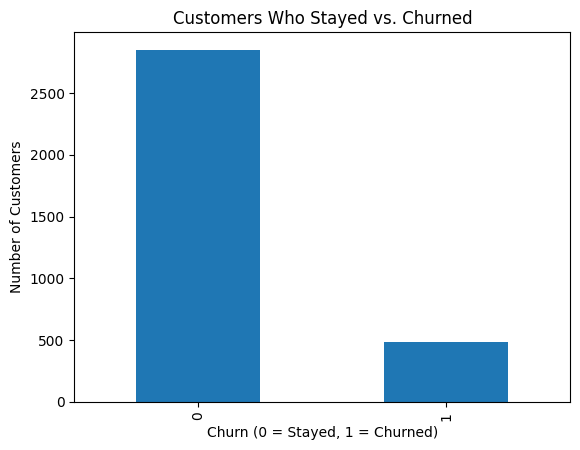

In [7]:
df["Churn"].value_counts().plot(kind="bar")
plt.title("Customers Who Stayed vs. Churned")
plt.xlabel("Churn (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.show()

**Observation:** The dataset has more customers who stayed than customers who left. This imbalance is important when we evaluate a prediction model.

## 5. Explore churn patterns

Let's compare churn with a few business-related features.

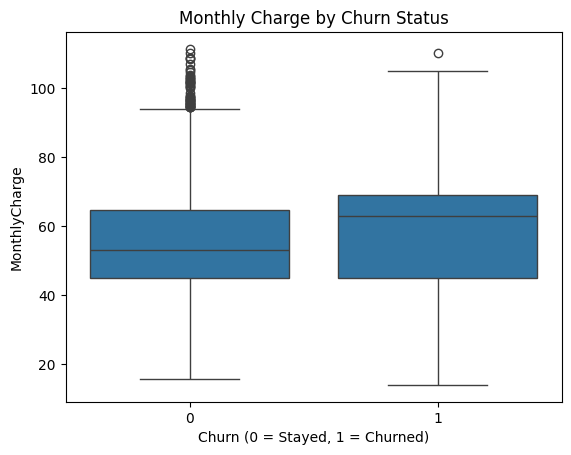

In [8]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharge")
plt.title("Monthly Charge by Churn Status")
plt.xlabel("Churn (0 = Stayed, 1 = Churned)")
plt.show()

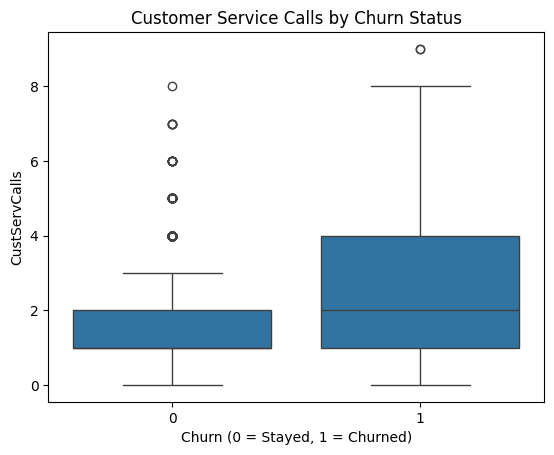

In [9]:
sns.boxplot(data=df, x="Churn", y="CustServCalls")
plt.title("Customer Service Calls by Churn Status")
plt.xlabel("Churn (0 = Stayed, 1 = Churned)")
plt.show()

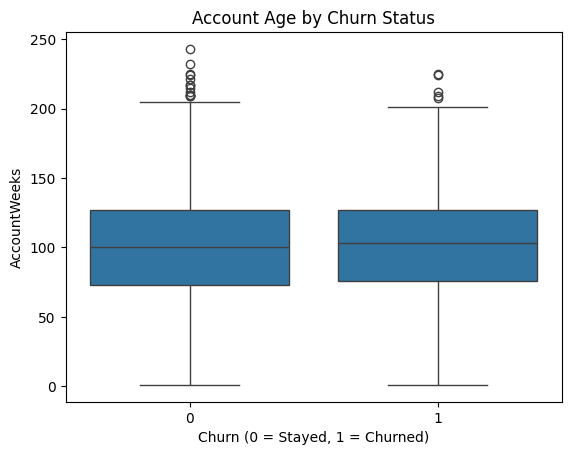

In [10]:
sns.boxplot(data=df, x="Churn", y="AccountWeeks")
plt.title("Account Age by Churn Status")
plt.xlabel("Churn (0 = Stayed, 1 = Churned)")
plt.show()

In [11]:
pd.crosstab(df["ContractRenewal"], df["Churn"], normalize="index").round(3)

Churn,0,1
ContractRenewal,,
0,0.576,0.424
1,0.885,0.115


In [12]:
pd.crosstab(df["DataPlan"], df["Churn"], normalize="index").round(3)

Churn,0,1
DataPlan,,
0,0.833,0.167
1,0.913,0.087


These comparisons show patterns in this dataset. They do not prove that a feature causes customers to leave.

## 6. Prepare the data for machine learning

We use `Churn` as the target we want to predict. All other columns are used as model features.

We keep part of the data for testing. The model will not see these rows during training.

In [13]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 2499
Testing rows: 834


## 7. Train Logistic Regression

Logistic Regression is a common starting model for classification.

It works better when numerical features are scaled, so we fit the scaler using the training data only.

In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

log_predictions = log_model.predict(X_test_scaled)
log_probabilities = log_model.predict_proba(X_test_scaled)[:, 1]

## 8. Train Random Forest

Random Forest is another classification model. It combines multiple decision trees and does not need feature scaling.

In [15]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

## 9. Compare the models

We will compare accuracy, precision, recall, F1-score, and ROC-AUC on the test set.

Because churn is less common than retention, do not judge the model by accuracy alone. Recall helps us understand how many actual churners the model finds, while precision tells us how many flagged customers actually churned.

In [16]:
model_results = []

for model_name, predictions, probabilities in [
    ("Logistic Regression", log_predictions, log_probabilities),
    ("Random Forest", rf_predictions, rf_probabilities)
]:
    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

model_results = pd.DataFrame(model_results).round(3)
model_results.sort_values("ROC-AUC", ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Random Forest,0.929,0.837,0.636,0.723,0.865
0,Logistic Regression,0.757,0.341,0.727,0.464,0.814


For this first comparison, the table shows how both models performed on the same held-out test set. For a production project, model selection should be confirmed using cross-validation on the training data before the final test evaluation.

## 10. Look at Logistic Regression coefficients

The coefficients show which features are associated with higher or lower predicted churn in this model. They should not be interpreted as proof of cause and effect.

In [17]:
coefficient_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_model.coef_[0]
})

coefficient_table = coefficient_table.sort_values(
    "Coefficient",
    ascending=False
)

coefficient_table

,Feature,Coefficient
4,CustServCalls,0.793961
5,DayMins,0.488070
7,MonthlyCharge,0.278884
8,OverageFee,0.262115
9,RoamMins,0.170537
0,AccountWeeks,0.065151
6,DayCalls,0.054832
3,DataUsage,-0.087124
2,DataPlan,-0.517549
1,ContractRenewal,-0.698646


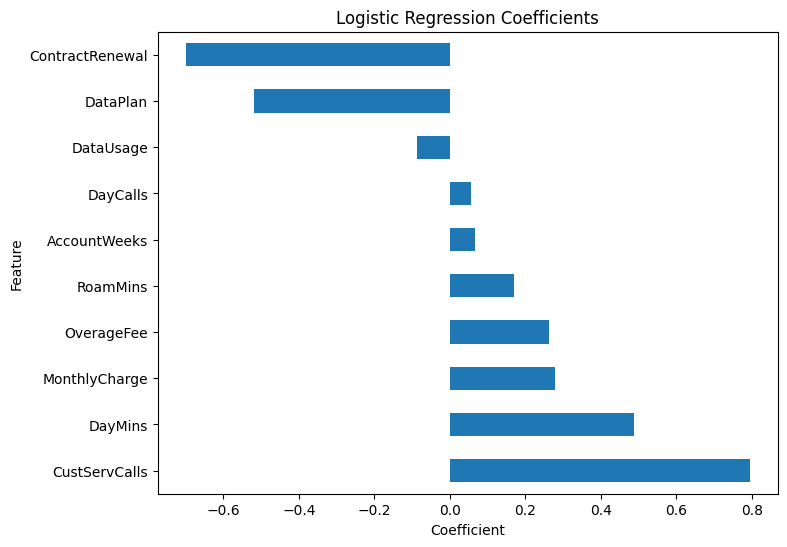

In [18]:
coefficient_table.plot(
    x="Feature",
    y="Coefficient",
    kind="barh",
    legend=False,
    figsize=(8, 6)
)
plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.show()

## 11. Business case: prioritize high-risk customers

A retention team may not have time to contact every customer. One simple idea is to start with the 10% of customers with the highest predicted churn probability.

Here, we use the Random Forest probabilities as an example. The 10% group is a prioritization scenario, not a promise that these customers will leave or that a campaign will save them.

In [19]:
risk_results = X_test.copy()
risk_results["Actual_Churn"] = y_test
risk_results["Predicted_Churn"] = rf_predictions
risk_results["Churn_Probability"] = rf_probabilities

risk_results = risk_results.sort_values(
    "Churn_Probability",
    ascending=False
).reset_index(drop=True)

top_10_count = max(1, int(len(risk_results) * 0.10))
top_10_customers = risk_results.head(top_10_count)

print("Customers in test set:", len(risk_results))
print("Customers in top 10% risk group:", len(top_10_customers))
print("Actual churn rate in test set:", round(risk_results["Actual_Churn"].mean(), 3))
print("Actual churn rate in top 10% group:", round(top_10_customers["Actual_Churn"].mean(), 3))

top_10_customers.head()

Customers in test set: 834
Customers in top 10% risk group: 83
Actual churn rate in test set: 0.145
Actual churn rate in top 10% group: 0.867


,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins,Actual_Churn,Predicted_Churn,Churn_Probability
0,71,1,0,0.0,3,290.4,108,71.0,12.70,10.1,1,1,0.985
1,133,1,0,0.0,2,295.0,141,70.0,11.18,12.9,1,1,0.975
2,113,1,0,0.0,1,272.1,111,70.0,13.43,8.5,1,1,0.975
3,111,1,0,0.0,1,294.7,90,76.0,14.73,10.8,1,1,0.970
4,60,1,0,0.0,2,289.8,101,71.0,12.78,11.7,1,1,0.970


## 12. Export results for Power BI

The next cells save two CSV files:
- `telecom_churn_test_predictions.csv`: test-set predictions, useful for checking model results.
- `telecom_churn_dashboard_data.csv`: all customers with predicted churn and risk levels, useful for building a dashboard.

The full-dataset predictions are for exploration and prioritization. Use the test set to report model performance.

In [20]:
output_folder = Path("/kaggle/working")
if not output_folder.exists():
    output_folder = Path(".")

test_results = X_test.copy()
test_results.insert(0, "Customer_Row_ID", X_test.index)
test_results["Actual_Churn"] = y_test
test_results["Predicted_Churn"] = rf_predictions
test_results["Churn_Probability"] = rf_probabilities

test_results = test_results.sort_values(
    "Churn_Probability",
    ascending=False
)

test_results.to_csv(
    output_folder / "telecom_churn_test_predictions.csv",
    index=False
)

print("Test predictions saved.")

Test predictions saved.


In [21]:
all_probabilities = rf_model.predict_proba(X)[:, 1]
all_predictions = rf_model.predict(X)

dashboard_data = X.copy()
dashboard_data.insert(0, "Customer_Row_ID", X.index)
dashboard_data["Actual_Churn"] = y
dashboard_data["Predicted_Churn"] = all_predictions
dashboard_data["Churn_Probability"] = all_probabilities

risk_50 = dashboard_data["Churn_Probability"].quantile(0.50)
risk_80 = dashboard_data["Churn_Probability"].quantile(0.80)
risk_90 = dashboard_data["Churn_Probability"].quantile(0.90)

dashboard_data["Churn_Risk_Level"] = "Low"
dashboard_data.loc[dashboard_data["Churn_Probability"] >= risk_50, "Churn_Risk_Level"] = "Medium"
dashboard_data.loc[dashboard_data["Churn_Probability"] >= risk_80, "Churn_Risk_Level"] = "High"
dashboard_data.loc[dashboard_data["Churn_Probability"] >= risk_90, "Churn_Risk_Level"] = "Very High"

dashboard_data.to_csv(
    output_folder / "telecom_churn_dashboard_data.csv",
    index=False
)

print("Dashboard data saved.")
print("Rows exported:", len(dashboard_data))
dashboard_data.head()

Dashboard data saved.
Rows exported: 3333


,Customer_Row_ID,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins,Actual_Churn,Predicted_Churn,Churn_Probability,Churn_Risk_Level
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0,0,0,0.005,Low
1,1,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7,0,0,0.055,Medium
2,2,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2,0,0,0.005,Low
3,3,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6,0,0,0.075,Medium
4,4,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1,0,0,0.285,High


## 13. Business recommendations

Based on the patterns found in the data, the company could:

1. Review customers who make many customer service calls and investigate whether their issues are being resolved.
2. Review contract renewal behavior and understand why some customers do not renew.
3. Use churn probabilities to prioritize retention outreach, while checking whether the model is reliable for the intended customer group.
4. Test retention campaigns on a smaller group and compare results with a suitable control group.

These are recommendations to investigate and test. The dataset does not include campaign costs, customer lifetime value, or actual campaign outcomes, so it cannot prove financial savings.

## 14. Limitations and next steps

- The dataset contains 3,333 rows and does not include a real customer ID or time-based history.
- Churn patterns are associations, not proof of causation.
- The top 10% risk group is a simple example of prioritization.
- The model predictions on the full dataset should not be used to report model performance.
- A next step is to build a Power BI report with an executive overview, churn drivers, and customer risk pages.

# Thank You